# Complexité empirique de v1CLD (B&B 1D)

Benchmark du temps de calcul par itération de sous-gradient pour `MKPCLDProblem` sur les instances Pisinger (weakly correlated, α=0.5).

`solve_zeta` résout un knapsack **1D exact** par B&B avec borne de Dantzig.  
Complexité par nœud : O(n). Nombre de nœuds : O(2^k) avec k = taille du core 1D.

**Variables étudiées :** n (items), m (contraintes), N (scénarios)

In [8]:
# ── Paramètres ────────────────────────────────────────────────────────────────
N_VALUES    = [5, 10, 20, 30, 50]
M_VALUES    = [2, 5, 10]
S_VALUES    = [50, 100, 500, 1000]

EPSILON     = 0.10
T_ITER      = 1
T_REPS      = 15
T_WARMUP    = 3

DATASET_DIR = 'data/knapsack/datasets-pisinger'
SEED        = 42
S_BENCH     = 100

In [9]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    ROOT = os.path.dirname(os.path.abspath(__vsc_ipynb_file__))
except NameError:
    ROOT = os.getcwd()

sys.path.insert(0, os.path.join(ROOT, 'lib'))
import v1ld_generic_cpp as cpp

def load_song(filepath, replication=0):
    rows = []
    with open(filepath) as f:
        for line in f:
            v = list(map(float, line.strip().split(',')))
            if int(v[4]) != replication: continue
            m, n = int(v[2]), int(v[3])
            A = np.array(v[5:5+m*n]).reshape(m, n)
            b = np.array(v[5+m*n:5+m*n+m])
            c = np.array(v[5+m*n+m:5+m*n+m+n])
            rows.append((A, b, c))
    N = len(rows)
    assert N > 0, f'Aucun scénario dans {filepath}'
    return rows[0][2], np.ones(N)/N, np.stack([r[0] for r in rows]), np.stack([r[1] for r in rows])

def chrono_cld_bb(c, p, A, b, epsilon, t_reps, t_warmup):
    prob = cpp.MKPCLDProblem(c, p, A, b, epsilon)
    for _ in range(t_warmup):
        cpp.solve_v1cld(prob, T=T_ITER, log_interval=0)
    times = []
    for _ in range(t_reps):
        t0 = time.perf_counter()
        cpp.solve_v1cld(prob, T=T_ITER, log_interval=0)
        times.append((time.perf_counter() - t0) * 1000)
    return np.mean(times), np.std(times)

print(f'Module : {cpp.__file__}')

Module : /Users/roman.lendormy/Documents/Cours/X25 - 3A/Stage/Learning_bounds_CCCP/lib/v1ld_generic_cpp.cpython-311-darwin.so


## 1. Collecte des mesures

In [10]:
records = []

for n in N_VALUES:
    for m in M_VALUES:
        fname = f'ccmk-song-pisinger-n{n}-m{m}-a50-we-r{SEED}-S{S_BENCH}.txt'
        fpath = os.path.join(ROOT, DATASET_DIR, fname)
        if not os.path.exists(fpath):
            print(f'MANQUANT : {fname}'); continue

        c, p, A, b = load_song(fpath)
        N_scen = len(p)
        W_max  = int(b.max())

        ms, std = chrono_cld_bb(c, p, A, b, EPSILON, T_REPS, T_WARMUP)

        records.append(dict(n=n, m=m, N=N_scen, W_max=W_max, ms=ms, std=std))
        print(f'n={n:3d} m={m:2d} N={N_scen:4d} W={W_max:6d}  v1CLD B&B={ms:.3f}±{std:.3f} ms')

df = pd.DataFrame(records)
print(f'\n{len(df)} combinaisons mesurées.')

n=  5 m= 2 N= 100 W=  1196  v1CLD B&B=0.532±0.141 ms
n=  5 m= 5 N= 100 W=  1859  v1CLD B&B=1.192±0.251 ms
n=  5 m=10 N= 100 W=  1884  v1CLD B&B=2.281±0.633 ms
n= 10 m= 2 N= 100 W=  3220  v1CLD B&B=0.557±0.119 ms
n= 10 m= 5 N= 100 W=  3220  v1CLD B&B=1.165±0.129 ms
n= 10 m=10 N= 100 W=  3220  v1CLD B&B=2.267±0.086 ms
n= 20 m= 2 N= 100 W=  5386  v1CLD B&B=0.961±0.187 ms
n= 20 m= 5 N= 100 W=  5537  v1CLD B&B=2.057±0.241 ms
n= 20 m=10 N= 100 W=  5537  v1CLD B&B=3.985±0.238 ms
n= 30 m= 2 N= 100 W=  8198  v1CLD B&B=1.214±0.085 ms
n= 30 m= 5 N= 100 W=  8198  v1CLD B&B=3.242±0.180 ms
n= 30 m=10 N= 100 W=  8198  v1CLD B&B=7.571±0.828 ms
n= 50 m= 2 N= 100 W= 13544  v1CLD B&B=3.178±0.297 ms
n= 50 m= 5 N= 100 W= 13544  v1CLD B&B=6.954±0.710 ms
n= 50 m=10 N= 100 W= 13544  v1CLD B&B=14.869±2.175 ms

15 combinaisons mesurées.


## 2. Effet de n

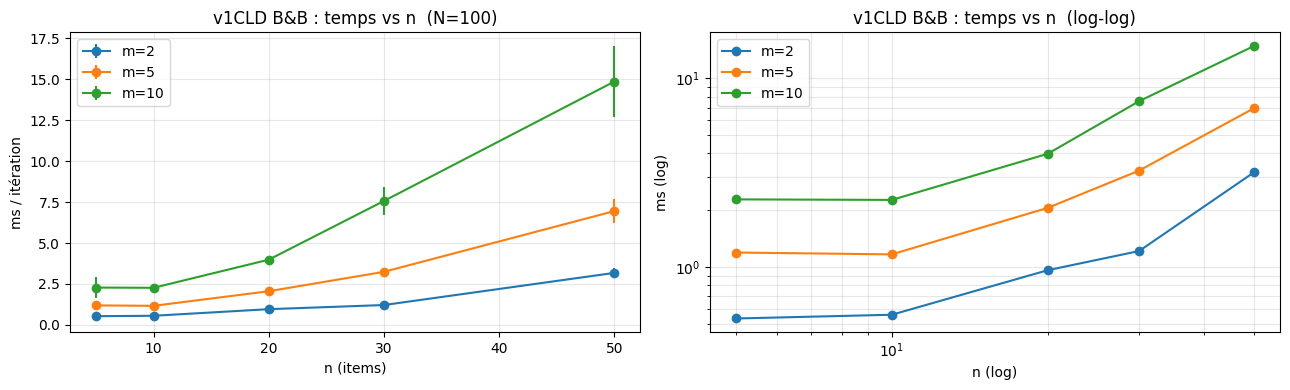

Exposants empiriques en n (pente log-log) :
  m=2 : pente = 0.74
  m=5 : pente = 0.77
  m=10 : pente = 0.84


In [11]:
colors = ['tab:blue', 'tab:orange', 'tab:green']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for m_val, color in zip(M_VALUES, colors):
    sub = df[df.m == m_val].sort_values('n')
    if sub.empty: continue
    axes[0].errorbar(sub.n, sub.ms, yerr=sub['std'], marker='o',
                     label=f'm={m_val}', color=color)
    axes[1].plot(sub.n, sub.ms, 'o-', label=f'm={m_val}', color=color)

axes[0].set_xlabel('n (items)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'v1CLD B&B : temps vs n  (N={S_BENCH})')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('n (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('v1CLD B&B : temps vs n  (log-log)')
axes[1].legend(); axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

print('Exposants empiriques en n (pente log-log) :')
for m_val in M_VALUES:
    sub = df[df.m == m_val].sort_values('n')
    if len(sub) < 3: continue
    slope = np.polyfit(np.log(sub.n.values.astype(float)),
                       np.log(sub.ms.values), 1)[0]
    print(f'  m={m_val} : pente = {slope:.2f}')

## 3. Effet de m

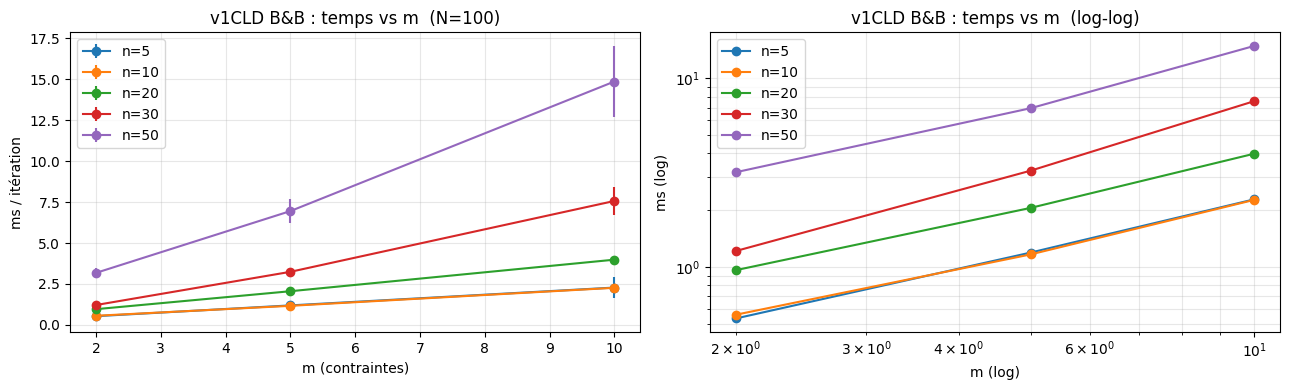

Exposants empiriques en m (pente log-log) :
  n=5 : pente = 0.90  (théorie: ~1)
  n=10 : pente = 0.87  (théorie: ~1)
  n=20 : pente = 0.88  (théorie: ~1)
  n=30 : pente = 1.13  (théorie: ~1)
  n=50 : pente = 0.95  (théorie: ~1)


In [12]:
colors5 = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple']
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for n_val, color in zip(N_VALUES, colors5):
    sub = df[df.n == n_val].sort_values('m')
    if sub.empty: continue
    axes[0].errorbar(sub.m, sub.ms, yerr=sub['std'], marker='o',
                     label=f'n={n_val}', color=color)
    axes[1].plot(sub.m, sub.ms, 'o-', label=f'n={n_val}', color=color)

axes[0].set_xlabel('m (contraintes)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'v1CLD B&B : temps vs m  (N={S_BENCH})')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('m (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('v1CLD B&B : temps vs m  (log-log)')
axes[1].legend(); axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

print('Exposants empiriques en m (pente log-log) :')
for n_val in N_VALUES:
    sub = df[df.n == n_val].sort_values('m')
    if len(sub) < 3: continue
    slope = np.polyfit(np.log(sub.m.values.astype(float)),
                       np.log(sub.ms.values), 1)[0]
    print(f'  n={n_val} : pente = {slope:.2f}  (théorie: ~1)')

## 4. Effet de N (scénarios)

N=   50  v1CLD B&B=0.961±0.109 ms
N=  100  v1CLD B&B=2.224±0.484 ms
N=  500  v1CLD B&B=11.853±0.717 ms
N= 1000  v1CLD B&B=25.848±2.827 ms


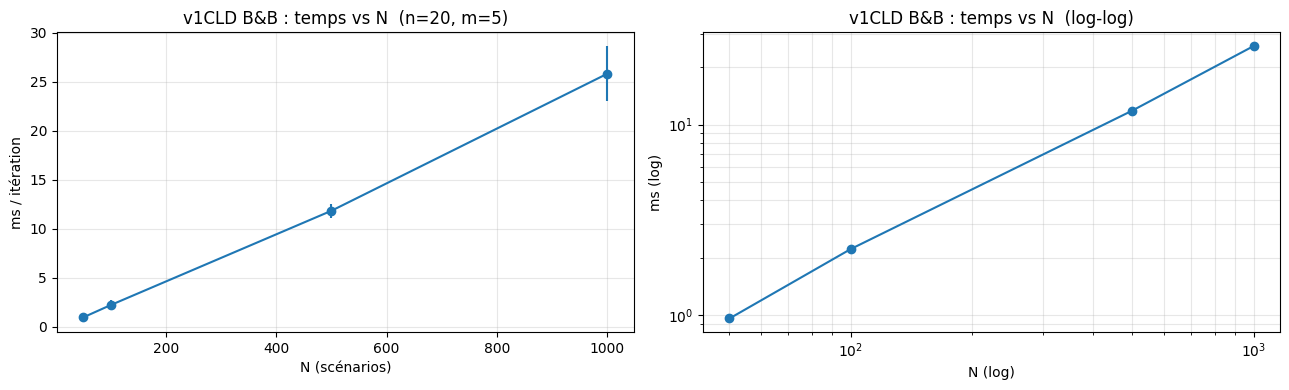

Exposant empirique en N : 1.09  (théorie: ~1)


In [13]:
N_FIX, M_FIX = 20, 5

records_s = []
for S in S_VALUES:
    fname = f'ccmk-song-pisinger-n{N_FIX}-m{M_FIX}-a50-we-r{SEED}-S{S}.txt'
    fpath = os.path.join(ROOT, DATASET_DIR, fname)
    if not os.path.exists(fpath): continue
    c, p, A, b = load_song(fpath)
    ms, std = chrono_cld_bb(c, p, A, b, EPSILON, T_REPS, T_WARMUP)
    records_s.append(dict(S=S, ms=ms, std=std))
    print(f'N={S:5d}  v1CLD B&B={ms:.3f}±{std:.3f} ms')

df_s = pd.DataFrame(records_s)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(df_s.S, df_s.ms, yerr=df_s['std'], marker='o')
axes[0].set_xlabel('N (scénarios)'); axes[0].set_ylabel('ms / itération')
axes[0].set_title(f'v1CLD B&B : temps vs N  (n={N_FIX}, m={M_FIX})')
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_s.S, df_s.ms, 'o-')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('N (log)'); axes[1].set_ylabel('ms (log)')
axes[1].set_title('v1CLD B&B : temps vs N  (log-log)')
axes[1].grid(True, alpha=0.3, which='both')

plt.tight_layout(); plt.show()

if len(df_s) >= 3:
    slope = np.polyfit(np.log(df_s.S.values.astype(float)),
                       np.log(df_s.ms.values), 1)[0]
    print(f'Exposant empirique en N : {slope:.2f}  (théorie: ~1)')

## 5. Tableau récapitulatif

In [14]:
print(df[['n', 'm', 'N', 'W_max', 'ms', 'std']].to_string(
    index=False, float_format=lambda x: f'{x:.3f}'))

 n  m   N  W_max     ms   std
 5  2 100   1196  0.532 0.141
 5  5 100   1859  1.192 0.251
 5 10 100   1884  2.281 0.633
10  2 100   3220  0.557 0.119
10  5 100   3220  1.165 0.129
10 10 100   3220  2.267 0.086
20  2 100   5386  0.961 0.187
20  5 100   5537  2.057 0.241
20 10 100   5537  3.985 0.238
30  2 100   8198  1.214 0.085
30  5 100   8198  3.242 0.180
30 10 100   8198  7.571 0.828
50  2 100  13544  3.178 0.297
50  5 100  13544  6.954 0.710
50 10 100  13544 14.869 2.175
